<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Visión por Computadora II
## Detección en imágenes fisheye: comparación final del 2×2

### Objetivo

Junta las cuatro ramas en una sola tabla, medidas **igual**:

| | sin fine-tuning | con fine-tuning |
|---|---|---|
| **sin rectificar** | Rama 1 | Rama 3 |
| **rectificado** | Rama 2 | Rama 4 |

* **Misma inferencia.** Las cuatro corren acá, en la misma máquina, con el flujo de `predecir_test` de `finetune_utils.py` (el que usó la rama 4): leer la imagen (fuera de la medición), preprocesar (la proyección cilíndrica en las ramas 2 y 4), detectar y posprocesar (llevar las cajas de vuelta a la fisheye en las ramas 2 y 4). Diez pasadas de calentamiento antes de medir. Así la latencia de las cuatro se puede comparar.
* **Mismo evaluador.** Las métricas salen de `evaluar` de `fisheye_utils.py`, sobre las mismas 1000 imágenes y el mismo ground truth, por ángulo de incidencia θ (la métrica del paper, cortes congelados en 68,3° y 80,7°) y por radio normalizado.
* **No se entrena ni se elige nada.** Usa los pesos finales de cada rama. Volver a correr el test con pesos ya fijos no cambia ninguna decisión.

Todos usan YOLO11m: pre-entrenado en COCO en las ramas 1 y 2, y fine-tuneado 30 épocas en las ramas 3 (sobre la fisheye) y 4 (sobre la cilíndrica).

### Imports y configuración

In [16]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import platform
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from matplotlib.patches import FancyBboxPatch, Rectangle

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from fisheye_utils import (
    ANILLOS, ANILLOS_THETA, CONF, DEVICE, IMGSZ, NOMBRES_ANILLOS,
    a_clases_tp, cargar_test, detector_yolo, evaluar, radio, theta,
)
import finetune_utils as ft

In [17]:
SALIDAS = RAIZ / "outputs/comparacion"
SALIDAS.mkdir(parents=True, exist_ok=True)

COCO = RAIZ / "yolo11m.pt"  # YOLO11m pre-entrenado en COCO
PESOS = {
    "rama1": COCO,
    "rama2": COCO,
    "rama3": RAIZ / "outputs/rama3/mac/rama3_base/weights/best.pt",  # fine-tuning sobre la fisheye
    "rama4": RAIZ / "outputs/rama4/train/yolo11m/weights/best.pt",   # fine-tuning sobre la cilindrica
}
PROYECCION = {"rama1": "fisheye", "rama2": "cilindrica", "rama3": "fisheye", "rama4": "cilindrica"}
ENTRENADA = {"rama1": False, "rama2": False, "rama3": True, "rama4": True}
NOMBRE = {"rama1": "Rama 1 · sin rectificar ni entrenar", "rama2": "Rama 2 · cilíndrica",
          "rama3": "Rama 3 · fine-tuning", "rama4": "Rama 4 · cilíndrica + fine-tuning"}
CORTO = {"rama1": "Rama 1", "rama2": "Rama 2", "rama3": "Rama 3", "rama4": "Rama 4"}

# mAP@50 y mAP@50-95 globales que reporto cada rama en su notebook, para chequear que aca se reproducen
REFERENCIA = {"rama1": (0.378, 0.239), "rama2": (0.418, 0.155), "rama3": (0.659, 0.430), "rama4": (0.521, 0.172)}


def chip():
    if platform.system() == "Darwin":
        r = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True)
        if r.stdout.strip():
            return r.stdout.strip()
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor()


HARDWARE = f"{chip()} ({DEVICE})"
for rama, peso in PESOS.items():
    assert Path(peso).is_file(), f"faltan los pesos de {rama}: {peso}"
print(f"hardware: {HARDWARE} | torch {torch.__version__} | ultralytics {ultralytics.__version__}")
print(f"imgsz: {IMGSZ} | conf: {CONF} | cortes de theta: {np.round(ANILLOS_THETA[1:3], 1)} | cortes de radio: {np.round(ANILLOS[1:3], 3)}")

hardware: Apple M4 Max (mps) | torch 2.14.0 | ultralytics 8.4.164
imgsz: 640 | conf: 0.01 | cortes de theta: [       68.3        80.7] | cortes de radio: [      0.333       0.667]


### Test

Las 1000 imágenes del Drive con el ground truth de `cargar_test`, el mismo para las cuatro ramas. Por θ, cada anillo tiene que quedar con unas 3970 cajas.

In [18]:
test = cargar_test()
th_gt = np.concatenate([theta(f.gt_cajas, f) for f in test.itertuples()])
r_gt = np.concatenate([radio(f.gt_cajas, f) for f in test.itertuples()])
print(f"test: {len(test)} imagenes | {len(th_gt)} cajas")
pd.DataFrame({
    "cajas por theta": pd.cut(th_gt, ANILLOS_THETA, labels=NOMBRES_ANILLOS, right=False).value_counts().sort_index(),
    "cajas por radio": pd.cut(r_gt, ANILLOS, labels=NOMBRES_ANILLOS, right=False).value_counts().sort_index(),
})

test: 1000 imagenes en el manifest | presentes: 1000 | faltan 0
test: 1000 imagenes | 11910 cajas


,cajas por theta,cajas por radio
centro,3970,1887
medio,3970,6656
periferia,3970,3367


### Inferencia

Para las ramas 1 y 2 el detector es el de COCO y traduzco sus clases a las del TP dentro de la misma llamada (suma menos de 0,1 ms). Las ramas 3 y 4 ya salen con las clases del TP. Las predicciones quedan en `outputs/comparacion/` y, si el kernel se reinicia, se leen de ahí sin volver a correr.

In [19]:
def detector(rama):
    if ENTRENADA[rama]:
        return ft.detector_ft("yolo11m", PESOS[rama])  # fine-tuneado: ya devuelve las clases del TP
    detectar, coco = detector_yolo(str(PESOS[rama]))
    return lambda img: a_clases_tp(*detectar(img), coco)  # COCO -> vehicle, person, two_wheeler


def progreso(rama):
    t0 = time.perf_counter()

    def mostrar(hechas, total):
        if hechas % 250 == 0 or hechas == total:
            print(f"  {rama}: {hechas}/{total} ({time.perf_counter() - t0:.0f} s)")
    return mostrar


preds = {}
for rama in PESOS:
    preds[rama] = ft.predecir_test(rama, detector(rama), test, SALIDAS, proyeccion=PROYECCION[rama],
                                   progreso=progreso(rama))
    print(f"{rama} ({PROYECCION[rama]}): {sum(len(c) for c in preds[rama]['clases'])} detecciones")

rama1 (fisheye): 50090 detecciones
rama2 (cilindrica): 45113 detecciones
rama3 (fisheye): 60096 detecciones
rama4 (cilindrica): 48507 detecciones


### Chequeo: cada rama reproduce su número

In [20]:
glob = {rama: evaluar(p, test) for rama, p in preds.items()}
chequeo = pd.DataFrame({
    rama: {"mAP50": m50, "mAP50 en su notebook": REFERENCIA[rama][0],
           "mAP50-95": m5095, "mAP50-95 en su notebook": REFERENCIA[rama][1]}
    for rama, (m50, m5095) in glob.items()
}).T
chequeo["diferencia mAP50"] = chequeo["mAP50"] - chequeo["mAP50 en su notebook"]
fuera = chequeo.index[chequeo["diferencia mAP50"].abs() > 0.01].tolist()
print("todas las ramas reproducen su global" if not fuera else f"ATENCION, no reproducen su global: {fuera}")
chequeo.round(3)

todas las ramas reproducen su global


,mAP50,mAP50 en su notebook,mAP50-95,mAP50-95 en su notebook,diferencia mAP50
rama1,0.378,0.378,0.239,0.239,-0.000
rama2,0.418,0.418,0.155,0.155,0.000
rama3,0.659,0.659,0.430,0.430,0.000
rama4,0.522,0.521,0.172,0.172,0.001


### Métricas por anillo

La tabla principal es por θ, la métrica del paper. La de radio normalizado es la que reportaron las ramas 2 y 4 en sus notebooks y sirve para comparar con esos números. En las dos, una caja cae en el anillo de su centro, y para cada anillo se filtran el ground truth y las predicciones (no el esquema *ignore* de COCO): lo mismo para las cuatro ramas.

In [21]:
def tabla(por):
    filas = []
    for rama, p in preds.items():
        m50, m5095 = glob[rama]
        f = {"rama": rama, "mAP50": m50, "mAP50-95": m5095}
        for i, a in enumerate(NOMBRES_ANILLOS):
            f[f"mAP50 {a}"], f[f"mAP50-95 {a}"] = evaluar(p, test, anillo=i, por=por)
        f["caida mAP50 centro->periferia"] = 1 - f["mAP50 periferia"] / f["mAP50 centro"]
        filas.append(f)
    return pd.DataFrame(filas).set_index("rama")


res = {por: tabla(por) for por in ("theta", "radio")}
for por, t in res.items():
    t.to_csv(SALIDAS / f"resultados_{por}.csv")
res["theta"].rename(index=NOMBRE).round(3)

,mAP50,mAP50-95,mAP50 centro,mAP50-95 centro,mAP50 medio,mAP50-95 medio,mAP50 periferia,mAP50-95 periferia,caida mAP50 centro->periferia
rama,,,,,,,,,
Rama 1 · sin rectificar ni entrenar,0.378,0.239,0.532,0.347,0.417,0.269,0.160,0.092,0.699
Rama 2 · cilíndrica,0.418,0.155,0.514,0.229,0.385,0.124,0.291,0.097,0.434
Rama 3 · fine-tuning,0.659,0.430,0.693,0.454,0.652,0.447,0.591,0.368,0.147
Rama 4 · cilíndrica + fine-tuning,0.522,0.172,0.628,0.249,0.483,0.139,0.383,0.113,0.389


In [22]:
res["radio"].rename(index=NOMBRE).round(3)

,mAP50,mAP50-95,mAP50 centro,mAP50-95 centro,mAP50 medio,mAP50-95 medio,mAP50 periferia,mAP50-95 periferia,caida mAP50 centro->periferia
rama,,,,,,,,,
Rama 1 · sin rectificar ni entrenar,0.378,0.239,0.527,0.342,0.445,0.285,0.144,0.083,0.727
Rama 2 · cilíndrica,0.418,0.155,0.561,0.299,0.420,0.143,0.291,0.100,0.482
Rama 3 · fine-tuning,0.659,0.430,0.685,0.439,0.660,0.444,0.596,0.367,0.130
Rama 4 · cilíndrica + fine-tuning,0.522,0.172,0.672,0.324,0.523,0.159,0.389,0.120,0.421


### Efectos del diseño 2×2

Cada efecto es una resta entre dos celdas que difieren en un solo factor. La interacción compara el efecto de rectificar con y sin fine-tuning: si es negativa, rectificar aporta menos (o resta) cuando el modelo ya se entrenó con imágenes fisheye.

In [23]:
def efectos(v):
    return {
        "rectificar sin fine-tuning (2 − 1)": v["rama2"] - v["rama1"],
        "rectificar con fine-tuning (4 − 3)": v["rama4"] - v["rama3"],
        "fine-tuning sin rectificar (3 − 1)": v["rama3"] - v["rama1"],
        "fine-tuning con rectificar (4 − 2)": v["rama4"] - v["rama2"],
        "interacción (4 − 3) − (2 − 1)": (v["rama4"] - v["rama3"]) - (v["rama2"] - v["rama1"]),
    }


METRICAS_EFECTO = {
    "mAP50 global": res["theta"]["mAP50"],
    "mAP50 periferia (θ)": res["theta"]["mAP50 periferia"],
    "mAP50-95 global": res["theta"]["mAP50-95"],
    "mAP50-95 periferia (θ)": res["theta"]["mAP50-95 periferia"],
    "mAP50 periferia (radio)": res["radio"]["mAP50 periferia"],
}
ef = pd.DataFrame({m: efectos(v) for m, v in METRICAS_EFECTO.items()})
ef.to_csv(SALIDAS / "efectos_2x2.csv")
ef.round(3)

,mAP50 global,mAP50 periferia (θ),mAP50-95 global,mAP50-95 periferia (θ),mAP50 periferia (radio)
rectificar sin fine-tuning (2 − 1),0.041,0.131,-0.084,0.005,0.147
rectificar con fine-tuning (4 − 3),-0.138,-0.208,-0.258,-0.255,-0.206
fine-tuning sin rectificar (3 − 1),0.282,0.432,0.192,0.276,0.452
fine-tuning con rectificar (4 − 2),0.104,0.092,0.017,0.017,0.098
interacción (4 − 3) − (2 − 1),-0.178,-0.339,-0.174,-0.259,-0.354


### Latencia

Media por imagen en milisegundos, separada en preprocesamiento (proyección cilíndrica), detector y posprocesamiento (vuelta de las cajas a la fisheye). Las cuatro ramas en la misma máquina.

In [24]:
lat = pd.DataFrame({
    rama: {"pre": p["ms_pre"].mean(), "detector": p["ms_inf"].mean(), "post": p["ms_post"].mean()}
    for rama, p in preds.items()
}).T
lat["total"] = lat[["pre", "detector", "post"]].sum(axis=1)
lat["p95 total"] = [(preds[r]["ms_pre"] + preds[r]["ms_inf"] + preds[r]["ms_post"]).quantile(0.95) for r in lat.index]
lat["fps"] = 1e3 / lat["total"]
lat.to_csv(SALIDAS / "latencia.csv")
print(f"hardware: {HARDWARE}")
lat.rename(index=NOMBRE).round(2)

hardware: Apple M4 Max (mps)


,pre,detector,post,total,p95 total,fps
Rama 1 · sin rectificar ni entrenar,0.00,24.97,0.00,24.97,33.35,40.04
Rama 2 · cilíndrica,1.62,23.70,1.31,26.63,30.15,37.55
Rama 3 · fine-tuning,0.00,22.91,0.01,22.92,26.49,43.63
Rama 4 · cilíndrica + fine-tuning,1.67,25.40,1.48,28.56,36.79,35.02


### Por cámara

In [25]:
CAMARAS = ["FV", "MVL", "MVR", "RV"]
por_camara = pd.DataFrame({
    rama: {c: evaluar(p, test[test["camera"] == c])[0] for c in CAMARAS} for rama, p in preds.items()
}).T
por_camara.to_csv(SALIDAS / "por_camara.csv")
por_camara.rename(index=NOMBRE).rename(columns=lambda c: f"mAP50 {c}").round(3)

,mAP50 FV,mAP50 MVL,mAP50 MVR,mAP50 RV
Rama 1 · sin rectificar ni entrenar,0.521,0.259,0.264,0.495
Rama 2 · cilíndrica,0.498,0.354,0.363,0.474
Rama 3 · fine-tuning,0.701,0.603,0.653,0.671
Rama 4 · cilíndrica + fine-tuning,0.625,0.453,0.468,0.547


### Figuras

El mismo estilo que las figuras de test de la rama 3, y cada rama con su color en todas las figuras (las ramas 1, 2 y 3 conservan el que tenían ahí). Los colores se validaron como paleta categórica; como dos de ellos tienen poco contraste con el fondo, cada serie lleva además marcador propio y etiqueta directa.

In [26]:
SUPERFICIE, TINTA, TINTA2, APAGADO, GRILLA, EJE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLORES = {"rama1": "#eb6834", "rama2": "#1baf7a", "rama3": "#2a78d6", "rama4": "#e87ba4"}
MARCAS = {"rama1": "s", "rama2": "D", "rama3": "o", "rama4": "v"}
ANILLOS_ETIQUETA = ["centro\nθ < 68,3°", "medio\n68,3° – 80,7°", "periferia\nθ > 80,7°"]


def estilo(ax, grilla="y"):
    ax.set_facecolor(SUPERFICIE)
    ax.grid(axis=grilla, color=GRILLA, linewidth=1, linestyle="-")
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(EJE)
    ax.tick_params(colors=EJE, labelcolor=TINTA2)


def separar(valores, minimo):
    # posiciones de etiquetas sin superponerse: mantiene el orden y abre al menos `minimo` entre vecinas
    orden = sorted(range(len(valores)), key=lambda i: valores[i])
    pos = list(valores)
    for a, b in zip(orden, orden[1:]):
        pos[b] = max(pos[b], pos[a] + minimo)
    return pos

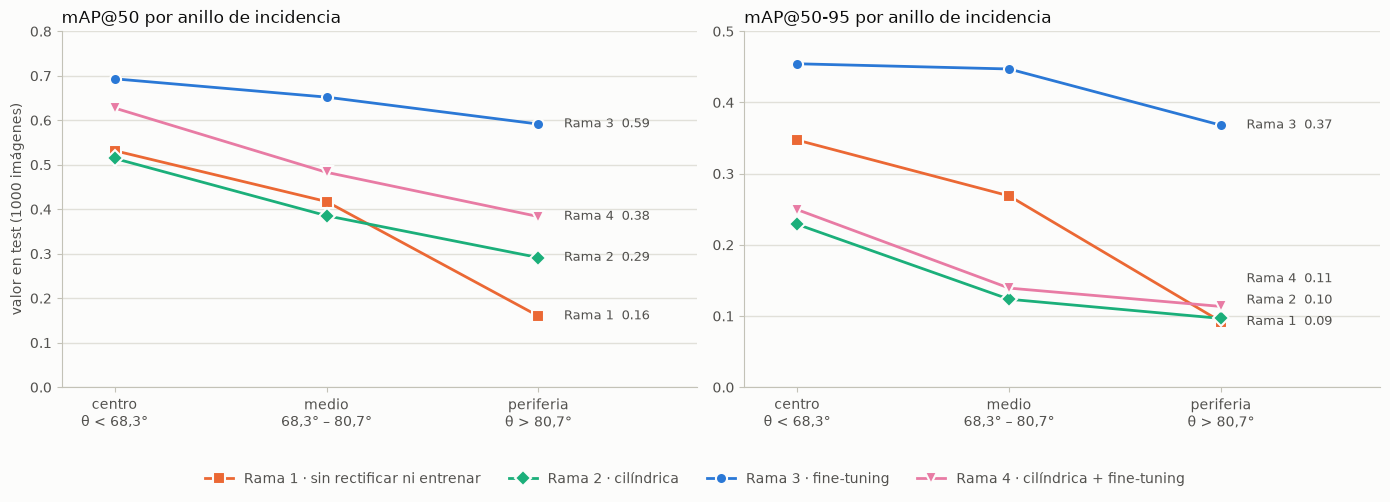

In [27]:
# figura 1: como cae cada rama del centro a la periferia
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), facecolor=SUPERFICIE)
x = np.arange(len(NOMBRES_ANILLOS))
for ax, (m, titulo, techo) in zip(axs, [("mAP50", "mAP@50 por anillo de incidencia", 0.8),
                                        ("mAP50-95", "mAP@50-95 por anillo de incidencia", 0.5)]):
    estilo(ax)
    finales = {}
    for rama in PESOS:
        y = [res["theta"].loc[rama, f"{m} {a}"] for a in NOMBRES_ANILLOS]
        ax.plot(x, y, color=COLORES[rama], marker=MARCAS[rama], markersize=8, linewidth=2,
                markeredgecolor=SUPERFICIE, markeredgewidth=1.5, label=NOMBRE[rama], zorder=3)
        finales[rama] = y[-1]
    ramas = list(finales)
    for rama, yy in zip(ramas, separar([finales[r] for r in ramas], techo * 0.06)):
        ax.annotate(f"{CORTO[rama]}  {finales[rama]:.2f}", (x[-1], finales[rama]), xytext=(x[-1] + 0.12, yy),
                    textcoords="data", va="center", color=TINTA2, fontsize=9)
    ax.set_xticks(x, ANILLOS_ETIQUETA)
    ax.set_xlim(-0.25, 2.75)
    ax.set_ylim(0, techo)
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=12)
axs[0].set_ylabel("valor en test (1000 imágenes)", color=TINTA2)
manijas, etiquetas = axs[0].get_legend_handles_labels()
fig.legend(manijas, etiquetas, loc="lower center", ncol=4, frameon=False, labelcolor=TINTA2, bbox_to_anchor=(0.5, -0.05))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(SALIDAS / "anillos_theta.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()

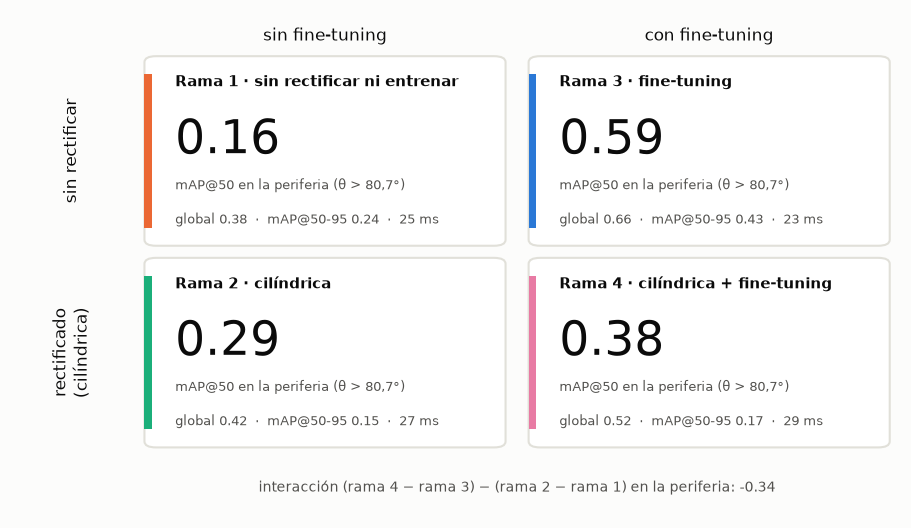

In [28]:
# figura 2: el 2x2 con el numero que importa (mAP@50 en la periferia, por theta)
CELDA = {"rama1": (0, 1), "rama3": (1, 1), "rama2": (0, 0), "rama4": (1, 0)}  # (columna: fine-tuning, fila: rectificar)
fig, ax = plt.subplots(figsize=(11.5, 6.6), facecolor=SUPERFICIE)
ax.set_facecolor(SUPERFICIE)
ax.set_xlim(-0.32, 2)
ax.set_ylim(-0.32, 2.2)
ax.axis("off")
for rama, (cx, cy) in CELDA.items():
    ax.add_patch(FancyBboxPatch((cx + 0.03, cy + 0.03), 0.94, 0.94, boxstyle="round,pad=0,rounding_size=0.03",
                                facecolor="#ffffff", edgecolor=GRILLA, linewidth=1.5))
    ax.add_patch(Rectangle((cx + 0.03, cy + 0.12), 0.02, 0.76, facecolor=COLORES[rama], edgecolor="none"))
    t, l = res["theta"].loc[rama], lat.loc[rama]
    ax.text(cx + 0.11, cy + 0.84, NOMBRE[rama], color=TINTA, fontsize=10.5, weight="bold", va="center")
    ax.text(cx + 0.11, cy + 0.55, f"{t['mAP50 periferia']:.2f}", color=TINTA, fontsize=34, va="center")
    ax.text(cx + 0.11, cy + 0.33, "mAP@50 en la periferia (θ > 80,7°)", color=TINTA2, fontsize=9, va="center")
    ax.text(cx + 0.11, cy + 0.16, f"global {t['mAP50']:.2f}  ·  mAP@50-95 {t['mAP50-95']:.2f}  ·  {l['total']:.0f} ms",
            color=TINTA2, fontsize=9, va="center")
for cx, texto in [(0.5, "sin fine-tuning"), (1.5, "con fine-tuning")]:
    ax.text(cx, 2.07, texto, ha="center", va="center", color=TINTA, fontsize=12)
for cy, texto in [(1.5, "sin rectificar"), (0.5, "rectificado\n(cilíndrica)")]:
    ax.text(-0.16, cy, texto, ha="center", va="center", color=TINTA, fontsize=12, rotation=90)
inter = ef.loc["interacción (4 − 3) − (2 − 1)", "mAP50 periferia (θ)"]
ax.text(1.0, -0.17, f"interacción (rama 4 − rama 3) − (rama 2 − rama 1) en la periferia: {inter:+.2f}",
        ha="center", va="center", color=TINTA2, fontsize=10)
fig.savefig(SALIDAS / "diseno_2x2.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()

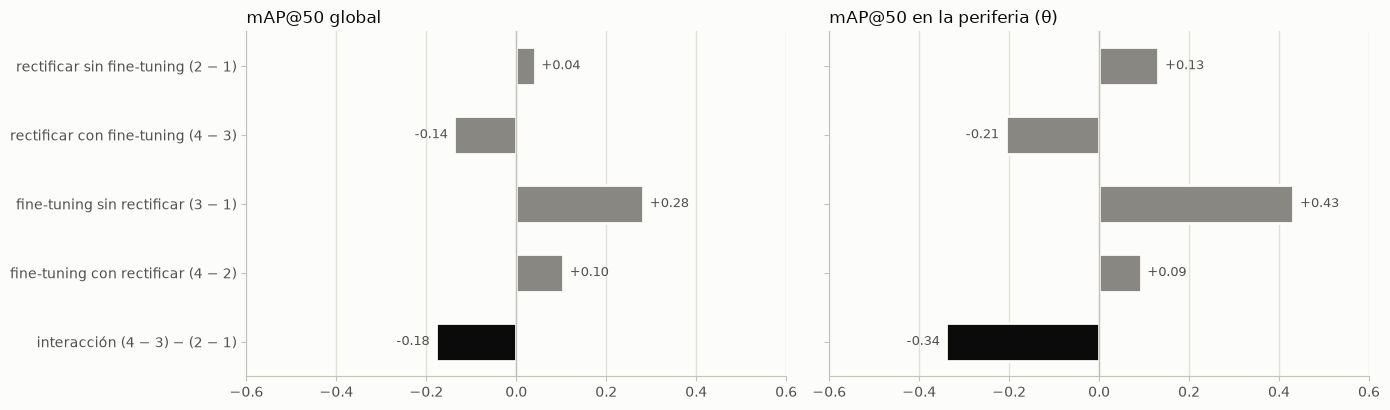

In [29]:
# figura 3: los efectos del 2x2 (barras hacia la derecha suman, hacia la izquierda restan)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), facecolor=SUPERFICIE, sharey=True)
filas = list(ef.index)[::-1]
for ax, m, titulo in zip(axs, ["mAP50 global", "mAP50 periferia (θ)"], ["mAP@50 global", "mAP@50 en la periferia (θ)"]):
    estilo(ax, grilla="x")
    v = ef.loc[filas, m].values
    colores = [TINTA if f.startswith("interacción") else APAGADO for f in filas]
    ax.barh(np.arange(len(filas)), v, height=0.55, color=colores, edgecolor=SUPERFICIE, linewidth=2)
    ax.axvline(0, color=EJE, linewidth=1)
    lim = max(0.6, np.abs(v).max() * 1.35)
    ax.set_xlim(-lim, lim)
    for i, val in enumerate(v):
        ax.text(val + (0.015 if val >= 0 else -0.015), i, f"{val:+.2f}", va="center",
                ha="left" if val >= 0 else "right", color=TINTA2, fontsize=9)
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=12)
axs[0].set_yticks(np.arange(len(filas)), filas)
fig.tight_layout()
fig.savefig(SALIDAS / "efectos_2x2.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()

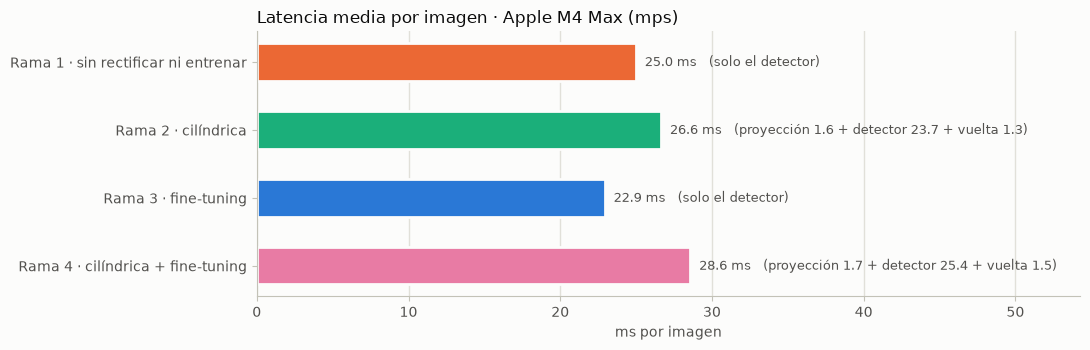

In [30]:
# figura 4: latencia por imagen en la misma maquina
fig, ax = plt.subplots(figsize=(11, 3.6), facecolor=SUPERFICIE)
estilo(ax, grilla="x")
ramas = list(PESOS)[::-1]
y = np.arange(len(ramas))
ax.barh(y, lat.loc[ramas, "total"], height=0.55, color=[COLORES[r] for r in ramas], edgecolor=SUPERFICIE, linewidth=2)
for i, r in enumerate(ramas):
    l = lat.loc[r]
    detalle = f"{l['total']:.1f} ms" + (f"   (proyección {l['pre']:.1f} + detector {l['detector']:.1f} + vuelta {l['post']:.1f})"
                                         if l["pre"] + l["post"] > 0.5 else "   (solo el detector)")
    ax.text(l["total"] + 0.6, i, detalle, va="center", color=TINTA2, fontsize=9)
ax.set_yticks(y, [NOMBRE[r] for r in ramas])
ax.set_xlim(0, lat["total"].max() * 1.9)
ax.set_xlabel("ms por imagen", color=TINTA2)
ax.set_title(f"Latencia media por imagen · {HARDWARE}", loc="left", color=TINTA, fontsize=12)
fig.tight_layout()
fig.savefig(SALIDAS / "latencia.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()

### Control: el mismo 2×2 con `eval_radial.py`

`eval_radial.py` mide con el esquema de COCO: en cada anillo, los objetos de otros anillos se ignoran en vez de filtrarse, y una detección que coincide con uno de ellos no cuenta como error. Es la reconstrucción del evaluador del equipo y coincide con `pycocotools` (`tools/validar_eval_radial.py`). Si las conclusiones dan igual con los dos esquemas, no dependen de cómo se trata el borde entre anillos.

Para la rama 4 comparo además con lo que dio el `eval_radial.py` original en el notebook de Nico (sus predicciones son de CUDA y estas de MPS, así que se esperan diferencias de milésimas).

In [31]:
import json
import subprocess

CONTROL = SALIDAS / "eval_radial"
filas_ignore = {}
for rama, p in preds.items():
    pj = CONTROL / f"pred_{rama}.json"
    ft.a_pred_json(p, pj)
    r = subprocess.run([sys.executable, str(RAIZ / "tools/eval_radial.py"), "--yolo-dir", str(RAIZ / "outputs/yolo_ds"),
                        "--split", "test", "--pred-json", str(pj), "--out", str(CONTROL / rama),
                        "--calibration", str(RAIZ / "config/calibration.json"), "--rings-file", str(RAIZ / "config/rings.json"),
                        "--etiqueta", rama, "--cruce-tamano"], capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-2000:]
    met = json.loads((CONTROL / rama / "metricas.json").read_text())
    filas_ignore[rama] = {f"{m} {f['rango']}": f[k] for f in met["filas"] if f["clase"] == "TODAS"
                          for m, k in (("mAP50", "AP50"), ("mAP50-95", "AP50_95"))}
ignore = pd.DataFrame(filas_ignore).T
ignore.to_csv(SALIDAS / "resultados_theta_eval_radial.csv")

COLS = ["mAP50 global", "mAP50 centro", "mAP50 medio", "mAP50 periferia", "mAP50-95 global", "mAP50-95 periferia"]
filtrado = res["theta"].rename(columns={"mAP50": "mAP50 global", "mAP50-95": "mAP50-95 global"})
pd.concat({"filtrado (fisheye_utils)": filtrado[COLS], "ignore (eval_radial)": ignore[COLS]}, axis=1).rename(index=NOMBRE).round(3)

filtrado (fisheye_utils)               \
                                                mAP50 global mAP50 centro   
Rama 1 · sin rectificar ni entrenar                    0.378        0.532   
Rama 2 · cilíndrica                                    0.418        0.514   
Rama 3 · fine-tuning                                   0.659        0.693   
Rama 4 · cilíndrica + fine-tuning                      0.522        0.628   

                                                                 \
                                    mAP50 medio mAP50 periferia   
Rama 1 · sin rectificar ni entrenar       0.417           0.160   
Rama 2 · cilíndrica                       0.385           0.291   
Rama 3 · fine-tuning                      0.652           0.591   
Rama 4 · cilíndrica + fine-tuning         0.483           0.383   

                                                                        \
                                    mAP50-95 global mAP50-95 periferia   
Rama 1 · sin rectificar ni entrenar           0.239              0.092   
Rama 2 · cilíndrica                           0.155              0.097   
Rama 3 · fine-tuning                          0.430              0.368   
Rama 4 · cilíndrica + fine-tuning             0.172              0.113   

                                    ignore (eval_radial)               \
                                            mAP50 global mAP50 centro   
Rama 1 · sin rectificar ni entrenar                0.378        0.541   
Rama 2 · cilíndrica                                0.418        0.528   
Rama 3 · fine-tuning                               0.659        0.701   
Rama 4 · cilíndrica + fine-tuning                  0.522        0.642   

                                                                 \
                                    mAP50 medio mAP50 periferia   
Rama 1 · sin rectificar ni entrenar       0.432           0.170   
Rama 2 · cilíndrica                       0.420           0.316   
Rama 3 · fine-tuning                      0.670           0.603   
Rama 4 · cilíndrica + fine-tuning         0.522           0.412   

                                                                        
                                    mAP50-95 global mAP50-95 periferia  
Rama 1 · sin rectificar ni entrenar           0.239              0.096  
Rama 2 · cilíndrica                           0.155              0.106  
Rama 3 · fine-tuning                          0.430              0.374  
Rama 4 · cilíndrica + fine-tuning             0.172              0.122

In [32]:
# los efectos del 2x2 con los dos esquemas
ef_ignore = pd.DataFrame({"mAP50 global": efectos(ignore["mAP50 global"]),
                          "mAP50 periferia (θ)": efectos(ignore["mAP50 periferia"]),
                          "mAP50-95 periferia (θ)": efectos(ignore["mAP50-95 periferia"])})
ef_ignore.to_csv(SALIDAS / "efectos_2x2_eval_radial.csv")
pd.concat({"filtrado": ef[["mAP50 global", "mAP50 periferia (θ)", "mAP50-95 periferia (θ)"]], "ignore": ef_ignore}, axis=1).round(3)

filtrado                      \
                                   mAP50 global mAP50 periferia (θ)   
rectificar sin fine-tuning (2 − 1)        0.041               0.131   
rectificar con fine-tuning (4 − 3)       -0.138              -0.208   
fine-tuning sin rectificar (3 − 1)        0.282               0.432   
fine-tuning con rectificar (4 − 2)        0.104               0.092   
interacción (4 − 3) − (2 − 1)            -0.178              -0.339   

                                                                ignore  \
                                   mAP50-95 periferia (θ) mAP50 global   
rectificar sin fine-tuning (2 − 1)                  0.005        0.041   
rectificar con fine-tuning (4 − 3)                 -0.255       -0.138   
fine-tuning sin rectificar (3 − 1)                  0.276        0.282   
fine-tuning con rectificar (4 − 2)                  0.017        0.104   
interacción (4 − 3) − (2 − 1)                      -0.259       -0.178   

                                                                               
                                   mAP50 periferia (θ) mAP50-95 periferia (θ)  
rectificar sin fine-tuning (2 − 1)               0.147                  0.010  
rectificar con fine-tuning (4 − 3)              -0.191                 -0.252  
fine-tuning sin rectificar (3 − 1)               0.433                  0.278  
fine-tuning con rectificar (4 − 2)               0.096                  0.016  
interacción (4 − 3) − (2 − 1)                   -0.337                 -0.261

In [33]:
# rama 4: eval_radial original (notebook de Nico, predicciones en CUDA) contra la reconstruccion (predicciones en MPS)
NICO_RAMA4 = {"mAP50 global": 0.521, "mAP50 centro": 0.642, "mAP50 medio": 0.521, "mAP50 periferia": 0.412,
              "mAP50-95 global": 0.172, "mAP50-95 centro": 0.254, "mAP50-95 medio": 0.152, "mAP50-95 periferia": 0.122}
nico = pd.DataFrame({"original (Nico)": NICO_RAMA4, "reconstruido": ignore.loc["rama4", list(NICO_RAMA4)]})
nico["diferencia"] = nico["reconstruido"] - nico["original (Nico)"]
print("coinciden con el original" if (nico["diferencia"].abs() <= 0.005).all() else "ATENCION: alguna diferencia mayor a 0.005")
nico.round(3)

coinciden con el original


,original (Nico),reconstruido,diferencia
mAP50 global,0.521,0.522,0.001
mAP50 centro,0.642,0.642,-0.000
mAP50 medio,0.521,0.522,0.001
mAP50 periferia,0.412,0.412,0.000
mAP50-95 global,0.172,0.172,0.000
mAP50-95 centro,0.254,0.255,0.001
mAP50-95 medio,0.152,0.151,-0.001
mAP50-95 periferia,0.122,0.122,-0.000


### Lectura

Las cuatro ramas reproducen el mAP global de su propio notebook (diferencia máxima 0,001), así que esta tabla compara exactamente lo que entregó cada rama. Los números son por θ salvo que se diga otra cosa.

1. **El problema.** Sin rectificar ni entrenar, YOLO11m pierde el 70% del mAP@50 del centro a la periferia (0,532 → 0,160).
2. **El fine-tuning es el factor dominante.** Sin rectificar, sube la periferia de 0,160 a 0,591 (+0,43) y el global de 0,378 a 0,659 (+0,28). Es la única rama en la que la caída del centro a la periferia queda chica (15%), y es la mejor en las cuatro cámaras: las laterales pasan de 0,26 a 0,60–0,65.
3. **Rectificar ayuda solo al modelo sin entrenar, y solo con IoU 0,5.** Sin fine-tuning, la cilíndrica sube la periferia de 0,160 a 0,291, pero baja un poco el centro (0,532 → 0,514) y el mAP@50-95 global cae de 0,239 a 0,155. Con fine-tuning, rectificar resta en todo: −0,14 de mAP@50 global, −0,21 en la periferia y −0,26 de mAP@50-95.
4. **La interacción es negativa y grande.** (rama 4 − rama 3) − (rama 2 − rama 1) es −0,18 de mAP@50 global y −0,34 en la periferia (−0,17 y −0,26 en mAP@50-95). La hipótesis del equipo era que rectificar aporta menos cuando el modelo ya vio datos fisheye; los datos muestran algo más fuerte: con fine-tuning, rectificar empeora. Por radio da lo mismo (−0,35 en la periferia), así que la conclusión no depende de cómo se definan los anillos.
5. **Por qué.** Las ramas rectificadas pierden sobre todo en mAP@50-95 (0,155 y 0,172 contra 0,239 y 0,430). La caja que vuelve de la cilíndrica a la fisheye encierra un contorno curvo y queda más grande que el objeto: aun con una detección perfecta, la IoU mediana es 0,65 en el anillo medio y la periferia (el control del techo de IoU de la rama 4). Además, los objetos fuera de la banda cilíndrica no se pueden detectar. Ningún entrenamiento recupera esas pérdidas.
6. **Latencia.** La proyección y la vuelta de las cajas suman unos 3 ms por imagen (1,6–1,7 ms + 1,3–1,5 ms), alrededor de un 12% sobre el detector. El detector tarda entre 23 y 25 ms en las cuatro ramas: es el mismo YOLO11m, y esa diferencia es del orden de la variación entre corridas (en los notebooks de las ramas 1 y 3, en otra sesión, había dado 17 ms). Lo firme es que el fine-tuning no agrega costo y la rectificación agrega unos 3 ms.

**Limitaciones.** Una corrida por rama, sin varianza entre semillas: diferencias del orden de 0,01–0,02 no son significativas. Los anillos filtran ground truth y predicciones en vez de usar el esquema *ignore* de COCO de `eval_radial.py`, igual para las cuatro ramas. La comparación se hace en la fisheye y con cajas, que es lo que usa el auto; con otra representación de salida (contornos o máscaras), las ramas rectificadas podrían perder menos.